<a href="https://colab.research.google.com/github/sgterrado/Need4Data-Blue-Bumper-Cars/blob/main/Trung/Data-Visualization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Data Cleaning

**Leading question:**

How does weather and time of day affect car accidents?

In [62]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import matplotlib.pyplot as plt
import missingno as msno

In [63]:
#Removes Science Notation from df.describe() and other functions
pd.set_option('display.float_format', lambda x: f'{x:.2f}')

In [64]:
df = pd.read_csv('/content/US_Accidents_March23_sampled_500k.csv', encoding ='latin1')

In [65]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500000 entries, 0 to 499999
Data columns (total 46 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   ID                     500000 non-null  object 
 1   Source                 500000 non-null  object 
 2   Severity               500000 non-null  int64  
 3   Start_Time             500000 non-null  object 
 4   End_Time               500000 non-null  object 
 5   Start_Lat              500000 non-null  float64
 6   Start_Lng              500000 non-null  float64
 7   End_Lat                279623 non-null  float64
 8   End_Lng                279623 non-null  float64
 9   Distance(mi)           500000 non-null  float64
 10  Description            499999 non-null  object 
 11  Street                 499309 non-null  object 
 12  City                   499981 non-null  object 
 13  County                 500000 non-null  object 
 14  State                  500000 non-nu

In [66]:
#Check for duplicates
df[df.duplicated()]

,ID,Source,Severity,Start_Time,End_Time,Start_Lat,Start_Lng,End_Lat,End_Lng,Distance(mi),...,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Turning_Loop,Sunrise_Sunset,Civil_Twilight,Nautical_Twilight,Astronomical_Twilight


There is no duplicate to drop.

In [67]:
#check for n/a rate
s = df.isna().mean()*100
s[s>0]


,0
End_Lat,44.08
End_Lng,44.08
Description,0.00
Street,0.14
City,0.00
Zipcode,0.02
Timezone,0.10
Airport_Code,0.29
Weather_Timestamp,1.53
Temperature(F),2.09


Most concerning column with missing data would be `End_lat` and `End_lng` for having more than 44% of missing value. For the dataset I will drop `End_lat` and `Eng_lng` for the alarming high amount of missing values and their not being able to contribute to our team leading question "How does weather and time of day affect car accidents?" I will also drop column ID for it is just an indentifier and doesn't give useful infomation.
Base on our team leading question  **how weather and time of day affet traffic?**, I will also drop the column that will not give us useful weather infomation : `Start_Lat, Start_lng, Source, Description,Street, Airport_Code, Bump, Crossing, Give_Way, Junction, Railway, Roundabout, Stop, Traffic_Calming, Traffic_Signal, Turning_Loop, Amenity, Weather_Timestamp`

In [68]:
#Drop columns with too many NaN values and ID
df = df.drop(columns = ['End_Time', 'End_Lat', 'End_Lng', 'ID', 'Start_Lat', 'Start_Lng', 'Description', 'Street',
                        'Airport_Code', 'Bump', 'Crossing', 'Give_Way',
                        'Junction', 'No_Exit', 'Railway', 'Roundabout',
                        'Station', 'Stop', 'Traffic_Calming', 'Traffic_Signal',
                        'Turning_Loop', 'Amenity', 'Source', 'Weather_Timestamp'])

Now I need to identify potential incorrect data type and fix them.

In [69]:
df['Country'].unique()

array(['US'], dtype=object)

I will drop `Timezone` and `Country` for all the entry in the dataset is set in the US and `Start_Time` and `End_Time` are recorded in local time.

In [70]:
df = df.drop(columns= ['Timezone', 'Country'])

In [71]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500000 entries, 0 to 499999
Data columns (total 20 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   Severity               500000 non-null  int64  
 1   Start_Time             500000 non-null  object 
 2   Distance(mi)           500000 non-null  float64
 3   City                   499981 non-null  object 
 4   County                 500000 non-null  object 
 5   State                  500000 non-null  object 
 6   Zipcode                499884 non-null  object 
 7   Temperature(F)         489534 non-null  float64
 8   Wind_Chill(F)          370983 non-null  float64
 9   Humidity(%)            488870 non-null  float64
 10  Pressure(in)           491072 non-null  float64
 11  Visibility(mi)         488709 non-null  float64
 12  Wind_Direction         488803 non-null  object 
 13  Wind_Speed(mph)        463013 non-null  float64
 14  Precipitation(in)      357384 non-nu

We only need 1 daytime/nightime identifier from `Sunrise_Sunset, Civil_Twilight, Astronomical_Twilight, Nautical_Twilight`




In [72]:
#find which will be the most optimal day/night identifier
df['Sunrise_Sunset'].isna().equals(df['Civil_Twilight'].isna()) and \
df['Sunrise_Sunset'].isna().equals(df['Nautical_Twilight'].isna()) and \
df['Sunrise_Sunset'].isna().equals(df['Astronomical_Twilight'].isna())



True

Since `Sunrise_Sunset, Civil_Twilight, Astronomical_Twilight, Nautical_Twilight` share the shame missing value pattern, I will keep the most understandable one which is the `Sunrise_Sunset`. And since the missing value rate in small (0.30%) I will drop those rows.

In [73]:
df = df.drop( columns= ['Civil_Twilight', 'Astronomical_Twilight',
                        'Nautical_Twilight'])

df.dropna(subset =['Sunrise_Sunset'], inplace = True)

In [74]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 498517 entries, 0 to 499999
Data columns (total 17 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Severity           498517 non-null  int64  
 1   Start_Time         498517 non-null  object 
 2   Distance(mi)       498517 non-null  float64
 3   City               498517 non-null  object 
 4   County             498517 non-null  object 
 5   State              498517 non-null  object 
 6   Zipcode            498402 non-null  object 
 7   Temperature(F)     488221 non-null  float64
 8   Wind_Chill(F)      369686 non-null  float64
 9   Humidity(%)        487561 non-null  float64
 10  Pressure(in)       489757 non-null  float64
 11  Visibility(mi)     487398 non-null  float64
 12  Wind_Direction     487496 non-null  object 
 13  Wind_Speed(mph)    461707 non-null  float64
 14  Precipitation(in)  356075 non-null  float64
 15  Weather_Condition  487587 non-null  object 
 16  Sunrise

We only need 1 Temperature measure so I will keep Temperature(F) and drop Wind_Chill(F) for it has high missing value rate.

In [75]:
df = df.drop( columns= ['Wind_Chill(F)'])

In [76]:
df.head(5)

,Severity,Start_Time,Distance(mi),City,County,State,Zipcode,Temperature(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Direction,Wind_Speed(mph),Precipitation(in),Weather_Condition,Sunrise_Sunset
0,2,2019-06-12 10:10:56,0.00,Zachary,East Baton Rouge,LA,70791-4610,77.00,62.00,29.92,10.00,NW,5.00,0.00,Fair,Day
1,2,2022-12-03 23:37:14.000000000,0.06,Sterling,Loudoun,VA,20164-2813,45.00,48.00,29.91,10.00,W,5.00,0.00,Fair,Night
2,2,2022-08-20 13:13:00.000000000,0.02,Lompoc,Santa Barbara,CA,93436,68.00,73.00,29.79,10.00,W,13.00,0.00,Fair,Day
3,2,2022-02-21 17:43:04,1.05,Austin,Mower,MN,55912,27.00,86.00,28.49,10.00,ENE,15.00,0.00,Wintry Mix,Day
4,2,2020-12-04 01:46:00,0.05,Bakersfield,Kern,CA,93305-2649,42.00,34.00,29.77,10.00,CALM,0.00,0.00,Fair,Night


 Found mismatch `Start_Time, Zipcode` layout, fixing that first


In [77]:
df['Start_Time'] = pd.to_datetime(
    df['Start_Time'],
    errors = 'coerce',
    format = 'mixed'
)


In [78]:
df.loc[~df['Zipcode'].astype(str).str.match(r'^\d{5}(-\d{4})?$', na=False)]['Zipcode'].unique()

array(['93247-94ND', '91105-18ND', '30518-17ND', nan, '93210-97ND',
       '44039-40ND', '91214-28ND', '44105-56ND', '44104-27ND',
       '30336-15ND', '32025-26ND', '29829-99ND', '30309-28ND',
       '93314-90ND', '32034-86ND', '23230-43ND', '77002-76ND',
       '34232-62ND', '33543-91ND', '70119-39ND', '23231-70ND',
       '23185-59ND', '23231-55ND', '30143-68ND', '93240-91ND',
       '23434-76ND', '93436-61ND', '93117-15ND', '30139-28ND',
       '29588-62ND', '93455-60ND', '23223-79ND', '44310-32ND',
       '75701-92ND', '30097-15ND', '29588-68ND', '11215-62ND',
       '48120-12ND', '11214-63ND', '90808-28ND', '17372-95ND',
       '30506-30ND', '23220-10ND', '23225-42ND', '22902-71ND',
       '95110-17ND', '30354-33ND', '17551-97ND', '75204-64ND',
       '19046-14ND', '29492-78ND', '44256-94ND', '77012-33ND',
       '19147-17ND', '32505-49ND', '23226-26ND', '30230-37ND',
       '77041-61ND', '93291-29ND', '75215-33ND', '17547-15ND',
       '75703-64ND', '44333-29ND', '30540-29ND', '

In [79]:
df['Zipcode'] = df['Zipcode'].astype(str).str[:5] #stip to get 5 zip standard

df['Zipcode'].value_counts(dropna = False)

,count
Zipcode,
27610,846
32819,788
33186,745
91761,739
70808,716
...,...
05001,1
44450,1
03261,1


In [80]:
df['Severity'].unique() # Nothing wrong here

array([2, 3, 4, 1])

In [81]:
df['State'].unique() # Nothing wrong here

array(['LA', 'VA', 'CA', 'MN', 'MA', 'OR', 'FL', 'TX', 'IN', 'MT', 'AL',
       'AZ', 'NY', 'NC', 'SC', 'KS', 'MI', 'CO', 'GA', 'MD', 'IL', 'PA',
       'NM', 'NV', 'NE', 'NJ', 'TN', 'UT', 'RI', 'MS', 'IA', 'WA', 'MO',
       'OH', 'OK', 'CT', 'DC', 'AR', 'WV', 'KY', 'WI', 'NH', 'WY', 'DE',
       'VT', 'ID', 'ME', 'ND', 'SD'], dtype=object)

In [82]:
df['Weather_Condition'].unique()

array(['Fair', 'Wintry Mix', 'Light Rain', 'Cloudy', 'Mostly Cloudy',
       'Partly Cloudy', 'Clear', 'Scattered Clouds', 'Fog', 'Overcast',
       'Light Snow', 'T-Storm', nan, 'Thunderstorms and Rain', 'Thunder',
       'Light Rain with Thunder', 'Rain', 'Showers in the Vicinity',
       'Mostly Cloudy / Windy', 'Heavy Rain', 'Cloudy / Windy',
       'Light Drizzle', 'Heavy T-Storm', 'Light Rain / Windy', 'Smoke',
       'Haze', 'Blowing Dust / Windy', 'N/A Precipitation',
       'Thunder in the Vicinity', 'Snow', 'Heavy Thunderstorms and Rain',
       'Shallow Fog', 'Light Freezing Drizzle', 'Fair / Windy',
       'Patches of Fog', 'Light Snow / Windy', 'Blowing Snow / Windy',
       'Thunderstorm', 'Drizzle', 'T-Storm / Windy',
       'Partly Cloudy / Windy', 'Heavy Rain / Windy',
       'Heavy Snow / Windy', 'Mist', 'Light Thunderstorms and Rain',
       'Rain / Windy', 'Light Freezing Rain', 'Heavy Snow',
       'Light Ice Pellets', 'Heavy T-Storm / Windy', 'Heavy Drizzle',
    

The `Weather_Condition` has too many catergories but all contain important weather information that cannot be combined. Because a thunderstorm snow is not just thunder nor just snow, so I will split the columns into `boolean` types of `|clear|rain|ice|windy|thunder|cloudy|smoke/dust|snow|` and then drop `Weather_Condition`

* squalls : a sudden increase in wind speed, might be accompanied by rain, storm, snow
* wintry mix : a rapid combination winter precipitation, such as snow, freezing rain and sleet







In [83]:
df['Weather_Condition'] = df['Weather_Condition'].replace('N/A Precipitation','')
df['Weather_Condition'] = df['Weather_Condition'].str.lower()

df['Clear_Weather'] = df['Weather_Condition'].str.contains('fair|clear')
df['Rain'] = df['Weather_Condition'].str.contains('rain|drizzle|shower')
df['Ice'] = df['Weather_Condition'].str.contains('freezing|hail|wintry|sleet|ice|pellet')
df['Windy'] = df['Weather_Condition'].str.contains('funnel|tornado|windy|whirlwind|squall')
df['Thunder'] = df['Weather_Condition'].str.contains('thunder|storm')
df['Cloudy'] = df['Weather_Condition'].str.contains('overcast|funnel|cloudy')
df['Smoke/Dust'] = df['Weather_Condition'].str.contains('smoke|sand|dust|haze|fog|ash|mist')
df['Snow'] = df['Weather_Condition'].str.contains('wintry|snow')

df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 498517 entries, 0 to 499999
Data columns (total 24 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   Severity           498517 non-null  int64         
 1   Start_Time         498517 non-null  datetime64[ns]
 2   Distance(mi)       498517 non-null  float64       
 3   City               498517 non-null  object        
 4   County             498517 non-null  object        
 5   State              498517 non-null  object        
 6   Zipcode            498517 non-null  object        
 7   Temperature(F)     488221 non-null  float64       
 8   Humidity(%)        487561 non-null  float64       
 9   Pressure(in)       489757 non-null  float64       
 10  Visibility(mi)     487398 non-null  float64       
 11  Wind_Direction     487496 non-null  object        
 12  Wind_Speed(mph)    461707 non-null  float64       
 13  Precipitation(in)  356075 non-null  float64      

<Axes: >

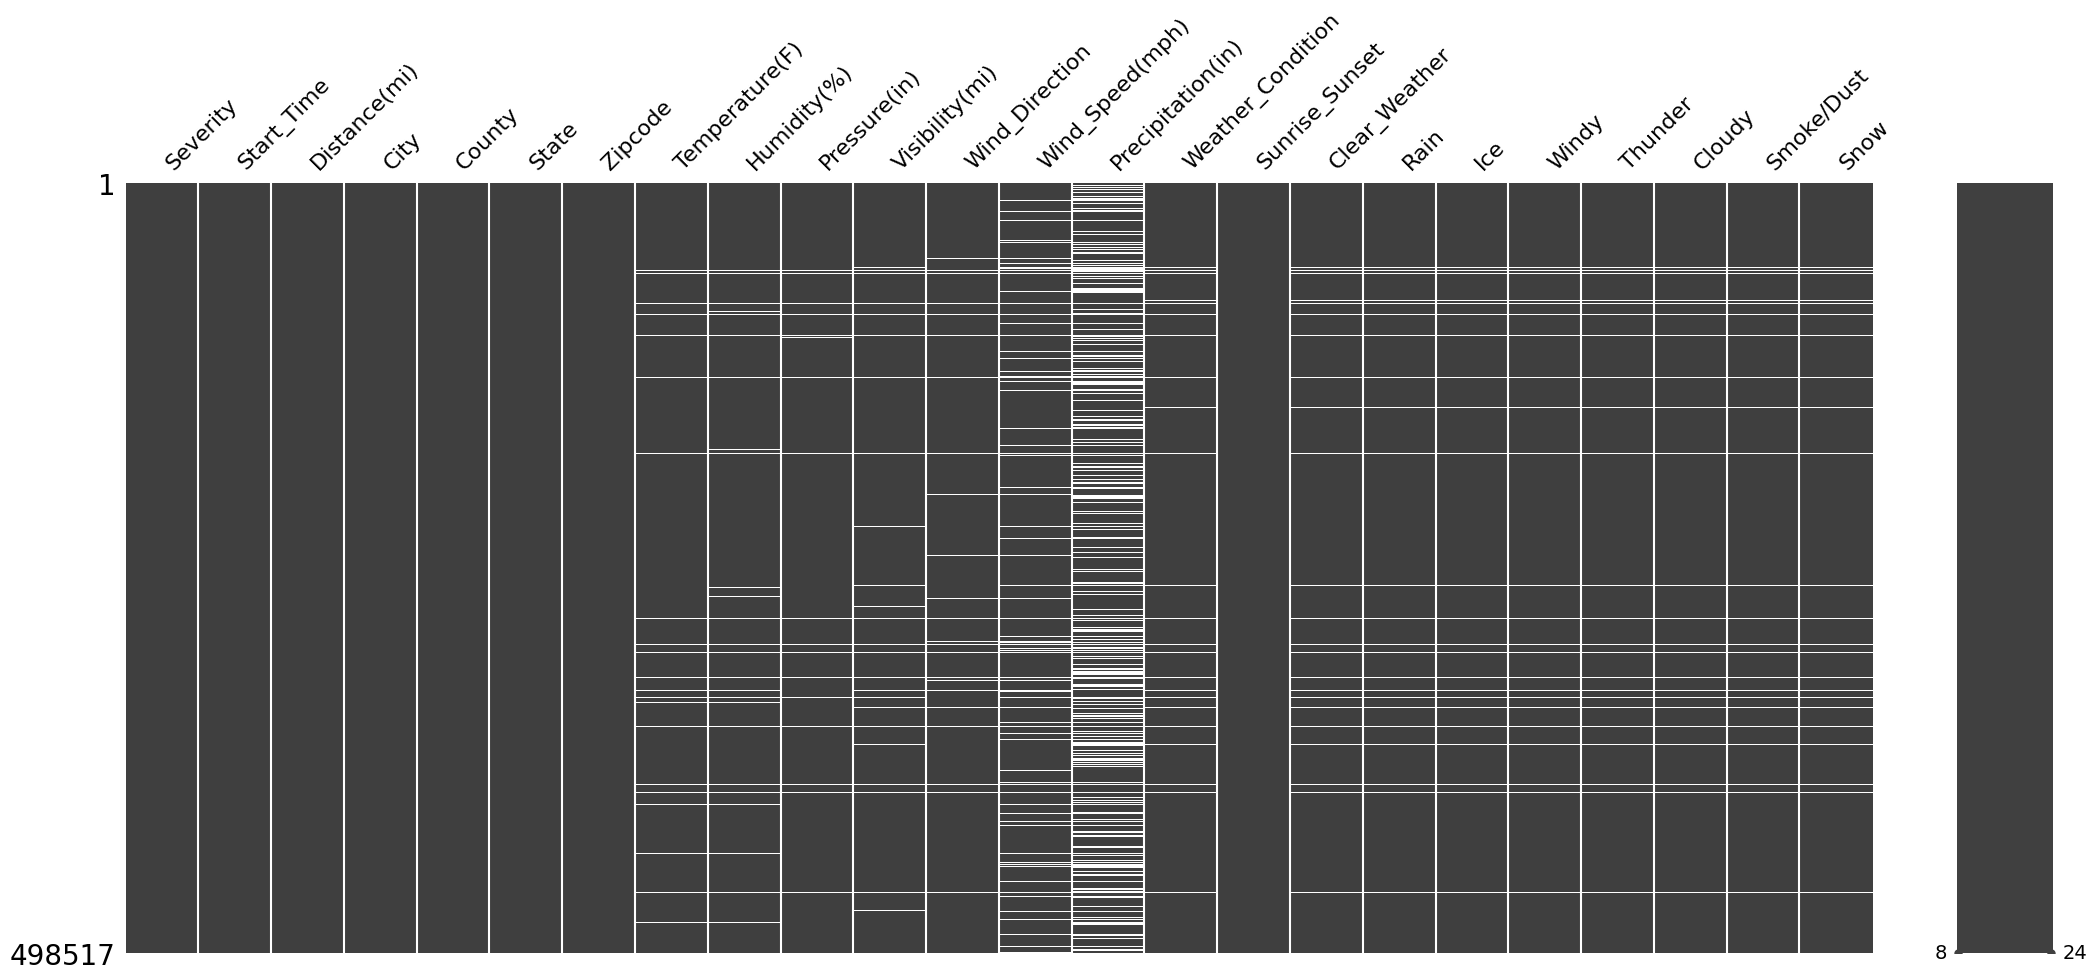

In [84]:
msno.matrix(df)

Because of `Weather_Condition` has NaN value, all the new tag will also show NaN at those specific entry.
Looking at the visualization, `Temperature(F), Wind_Chill(F),Humidity(%), Pressure, Visibility, Wind_direction, Wind_Speed, Precipitation(in), Weather_Condition` and all the new tags have a similar pattern on missing value (the straight line across). I will confirm this and drop those entry if they exist becasue weather infomation is unknown for those accident.

In [85]:
cols_to_check = ['Temperature(F)','Humidity(%)','Pressure(in)',
                 'Visibility(mi)', 'Wind_Direction', 'Wind_Speed(mph)',
                 'Precipitation(in)', 'Weather_Condition']

df[cols_to_check].isna().all(axis=1).mean() * 100 # check how much they exist in the dataset

np.float64(1.5074711594589552)

<Axes: >

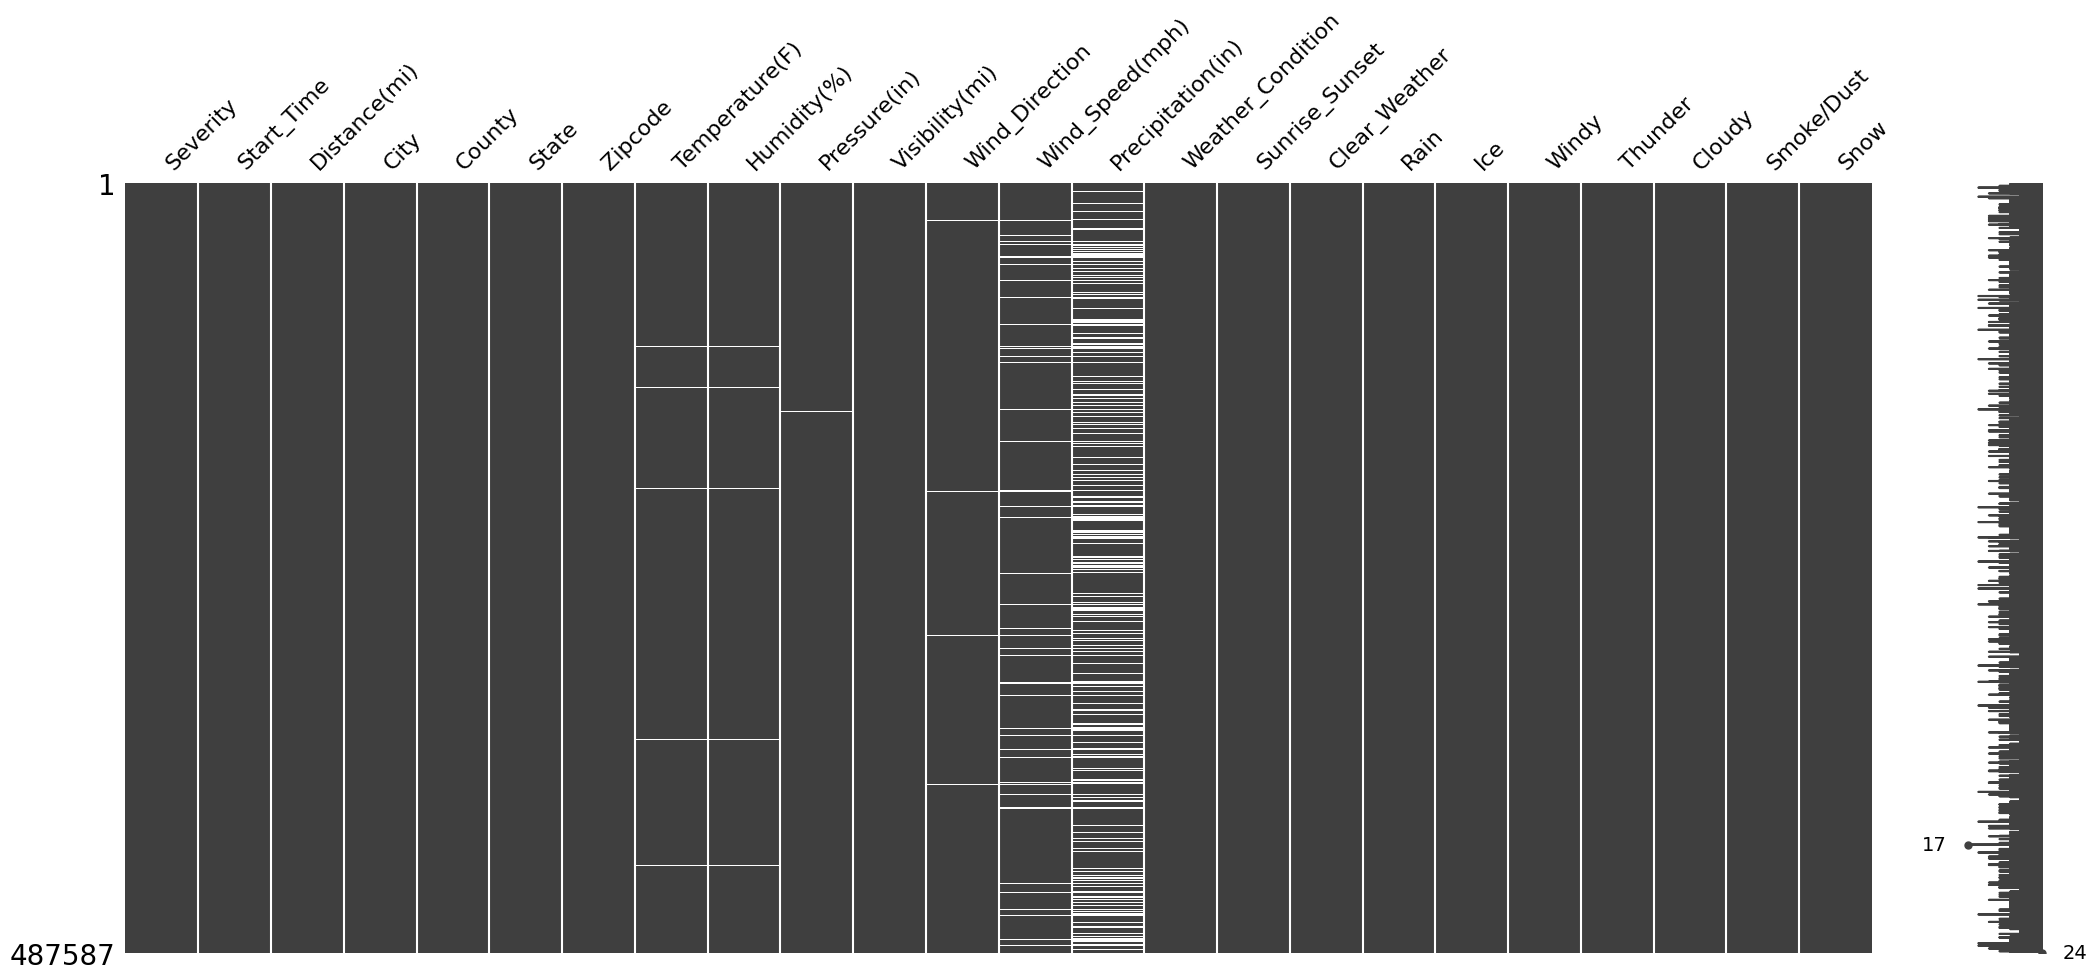

In [86]:
df = df.dropna(subset=['Temperature(F)','Humidity(%)','Pressure(in)',
                 'Visibility(mi)', 'Wind_Direction', 'Wind_Speed(mph)',
                 'Precipitation(in)', 'Weather_Condition'], how= 'all')

#drop NaN weather condition because we need the weather data
df.dropna(subset =['Weather_Condition'], inplace = True)

msno.matrix(df)


In [87]:
s = df.isna().mean()*100
s[s>0]

,0
Temperature(F),0.36
Humidity(%),0.49
Pressure(in),0.12
Visibility(mi),0.27
Wind_Direction,0.53
Wind_Speed(mph),5.60
Precipitation(in),27.35


In [88]:
df['Wind_Direction'].unique()

array(['NW', 'W', 'ENE', 'CALM', 'SW', 'VAR', 'S', 'E', 'WSW', 'NNE',
       'Variable', 'West', 'N', 'ESE', 'NNW', 'North', 'SSW', 'WNW', 'NE',
       'Calm', 'SE', 'East', 'SSE', 'South', nan], dtype=object)

In [89]:
df['Wind_Direction'] = df['Wind_Direction'].replace({
    "North" : "N",
    "East" : "E",
    "South" : "S",
    "Calm" : "CALM",
    "West" : "W",
    "Variable" : "VAR"
})

In [90]:
df['Wind_Direction'] = df['Wind_Direction'].fillna("Unknown")

In [91]:
df['Wind_Direction'].value_counts(dropna=False)

,count
Wind_Direction,
CALM,85715
S,38319
W,35482
N,28723
SSW,24641
E,24411
WNW,24192
NW,23761
SW,23536


In [92]:
df['Temperature(F)'].describe()

,Temperature(F)
count,485853.00
mean,61.66
std,18.99
min,-35.00
25%,49.00
50%,64.00
75%,76.00
max,207.00


IQR = 27, Upper Bound = Q3 +1.5IQR = 116.5 meaning any value > 116 is an outlier, such as 207
But there is places in the US that can have outdoor temperature up to 130°F so I will check and possibly remove base on that rather than using the upper bound. -35 is a reasonable temperature because someplace can reach -70°F
I will also replace NaN with median value to not affect the data much.

In [93]:
df[df['Temperature(F)'] > 120]['Temperature(F)']

,Temperature(F)
63069,140.00
193548,207.00
426439,196.00


In [94]:
df = df[df['Temperature(F)'] <=120] #drop the temperature outside 130°F
df['Temperature(F)'] = df['Temperature(F)'].fillna(df['Temperature(F)'].median())
df['Temperature(F)'].describe()

,Temperature(F)
count,485850.00
mean,61.66
std,18.98
min,-35.00
25%,49.00
50%,64.00
75%,76.00
max,117.00


`Precipitation(in)` has a high rate of missing value, assuming if the weather was clear/fair then `Precipitation(in)` should have been zero.
But if the weather tags for Rain, Snow then it should not be zero.

In [95]:
df['Precipitation(in)'].describe()

,Precipitation(in)
count,353037.00
mean,0.01
std,0.10
min,0.00
25%,0.00
50%,0.00
75%,0.00
max,10.09


In [96]:
df[df['Clear_Weather']]['Precipitation(in)'].isna().mean()*100

np.float64(26.24008026999909)

In [97]:
df[df['Cloudy']]['Precipitation(in)'].isna().mean()*100

np.float64(29.760716799193286)

In [98]:
df[df['Rain']]['Precipitation(in)'].isna().mean()*100

np.float64(5.211848518935133)

In [99]:
df[df['Smoke/Dust']]['Precipitation(in)'].isna().mean()*100

np.float64(25.466880097568414)

In [100]:
df[df['Snow']]['Precipitation(in)'].isna().mean()*100

np.float64(4.898108379786165)

In [101]:
df[df['Thunder']]['Precipitation(in)'].isna().mean()*100

np.float64(5.697653907214676)

In [102]:
df[df['Ice']]['Precipitation(in)'].isna().mean()*100

np.float64(6.240369799691833)

Examining the missing rate vs. the weather tags, it show that when `Rain`, `Snow`, `Thunder` or `Ice` is `True`, they are more likely to have a value. And when `Clear_Wheather, Cloudy` or `Smoke/Dust` it is more likely to NaN. I believe this show a pattern that NaN value is actually "no measuareble precipitation" recorded when it is not raining, snowing and in a storm. But because 75% of Precipitation is 0.0. indicating that these are the case of when precipitation cannot be measured. I will just leave the Precipitation as is and not replace all with 0.0.

In [103]:
s = df.isna().mean()*100
s[s>0]

,0
Humidity(%),0.13
Pressure(in),0.09
Visibility(mi),0.25
Wind_Speed(mph),5.55
Precipitation(in),27.34


In [104]:
df['Humidity(%)'].describe()

,Humidity(%)
count,485198.00
mean,64.83
std,22.82
min,1.00
25%,48.00
50%,67.00
75%,84.00
max,100.00


Humidity is in reasonable range so I will deal with the NaN

In [105]:
df['Humidity(%)'] = df['Humidity(%)'].fillna(df['Humidity(%)'].median())

In [106]:
df['Pressure(in)'].describe()

,Pressure(in)
count,485409.00
mean,29.54
std,1.00
min,2.99
25%,29.37
50%,29.86
75%,30.03
max,38.44


The highest record of air pressure in the US was 31.85in and lowest is 26.35 so a max of 38.44 and a min of 2.99 is definitely an invalid entry.

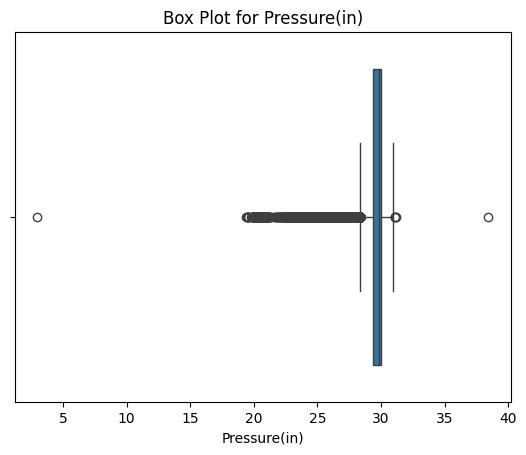

In [107]:
sns.boxplot(x=df['Pressure(in)'])
plt.title("Box Plot for Pressure(in)")
plt.show()

In [108]:
# check value outside of plausible range
print("Missing rate", ((df['Pressure(in)'] < 26.35) | (df['Pressure(in)'] > 32)).mean()*100)
print("Total of entry ", (((df['Pressure(in)'] < 26.35) | (df['Pressure(in)'] > 32)).sum()))

Missing rate 2.977873829371205
Total of entry  14468


Since there are too many out of range value of pressure and might not have too much impact on the weather data, I will convert all to NaN. If we need complete data, compute later.

In [109]:
df.loc[((df['Pressure(in)'] < 26.35) | (df['Pressure(in)'] > 32)), 'Pressure(in)'] = np.nan

In [110]:
df['Wind_Speed(mph)'].describe()

,Wind_Speed(mph)
count,458870.00
mean,7.68
std,5.43
min,0.00
25%,4.60
50%,7.00
75%,10.40
max,822.80


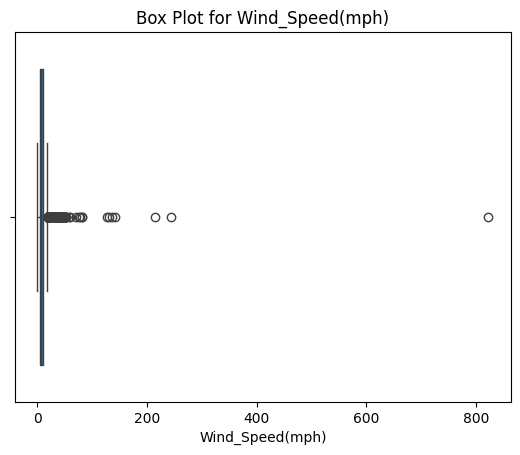

In [111]:
sns.boxplot(x=df['Wind_Speed(mph)'])
plt.title("Box Plot for Wind_Speed(mph)")
plt.show()

In [112]:
df[df['Wind_Speed(mph)']>321] #highest wind ever detected is 321mph

,Severity,Start_Time,Distance(mi),City,County,State,Zipcode,Temperature(F),Humidity(%),Pressure(in),...,Weather_Condition,Sunrise_Sunset,Clear_Weather,Rain,Ice,Windy,Thunder,Cloudy,Smoke/Dust,Snow
371110,3,2016-06-13 20:06:45,0.00,Pacoima,Los Angeles,CA,91331,71.60,53.00,30.06,...,clear,Night,True,False,False,False,False,False,False,False


In [113]:
df.loc[(df['Wind_Speed(mph)']>321), 'Wind_Speed(mph)'] = np.nan

In [114]:
df['Visibility(mi)'].describe()

,Visibility(mi)
count,484613.00
mean,9.09
std,2.70
min,0.00
25%,10.00
50%,10.00
75%,10.00
max,130.00


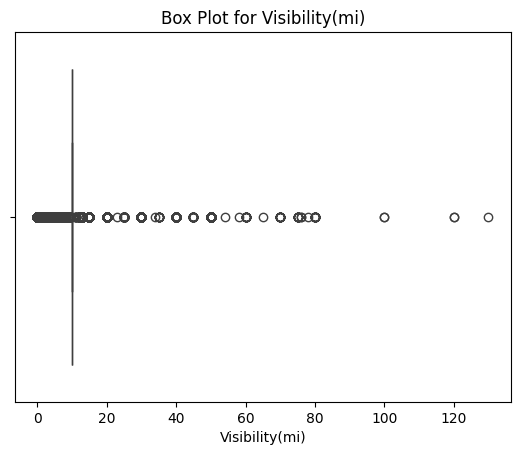

In [115]:
sns.boxplot(x=df['Visibility(mi)'])
plt.title("Box Plot for Visibility(mi)")
plt.show()

Since 75% of Visibility are 10, I suspect this to be the weather station visibility report ceiling. I will cap any thing above 100 at 10 because it could be a entry error. For any value >10 and <100 I will leave it as is. Missing value would be replace with 10 as it will not impact tthe overal pattern in the Visibility(mi).

In [116]:
df.loc[df['Visibility(mi)']>=100,'Visibility(mi)'] = 10
df['Visibility(mi)'] = df['Visibility(mi)'].fillna(10)

In [117]:
s = df.isna().mean()*100
s[s>0]

,0
Pressure(in),3.07
Wind_Speed(mph),5.55
Precipitation(in),27.34


For easier visualization I will separate the `Start_Time` into separate entities.

In [118]:
df['Month'] = df['Start_Time'].dt.month
df['Date'] = df['Start_Time'].dt.day
df['Year'] = df['Start_Time'].dt.year
df['Time_Hour'] = df['Start_Time'].dt.hour
df['Time_Minute'] = df['Start_Time'].dt.minute


#df = df.drop(columns= 'Start_Time')

df.head(5)

,Severity,Start_Time,Distance(mi),City,County,State,Zipcode,Temperature(F),Humidity(%),Pressure(in),...,Windy,Thunder,Cloudy,Smoke/Dust,Snow,Month,Date,Year,Time_Hour,Time_Minute
0,2,2019-06-12 10:10:56,0.00,Zachary,East Baton Rouge,LA,70791,77.00,62.00,29.92,...,False,False,False,False,False,6,12,2019,10,10
1,2,2022-12-03 23:37:14,0.06,Sterling,Loudoun,VA,20164,45.00,48.00,29.91,...,False,False,False,False,False,12,3,2022,23,37
2,2,2022-08-20 13:13:00,0.02,Lompoc,Santa Barbara,CA,93436,68.00,73.00,29.79,...,False,False,False,False,False,8,20,2022,13,13
3,2,2022-02-21 17:43:04,1.05,Austin,Mower,MN,55912,27.00,86.00,28.49,...,False,False,False,False,True,2,21,2022,17,43
4,2,2020-12-04 01:46:00,0.05,Bakersfield,Kern,CA,93305,42.00,34.00,29.77,...,False,False,False,False,False,12,4,2020,1,46


Do nighttime accidents become more severe during rainy weather?

In [119]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

analysis_df = df[
    ["Severity", "Sunrise_Sunset", "Rain"]
].dropna()

analysis_df = analysis_df[
    analysis_df["Sunrise_Sunset"].isin(["Day", "Night"])
]

analysis_df["Serious_Accident"] = analysis_df["Severity"] >= 3

summary = (
    analysis_df
    .groupby(["Sunrise_Sunset", "Rain"])
    .agg(
        Total_Accidents=("Severity", "count"),
        Serious_Accidents=("Serious_Accident", "sum")
    )
    .reset_index()
)

summary["Serious_Rate"] = (
    summary["Serious_Accidents"]
    / summary["Total_Accidents"]
    * 100
)

summary["Weather"] = summary["Rain"].map({
    True: "Rainy",
    False: "Not Rainy"
})

print(summary)

  Sunrise_Sunset   Rain  Total_Accidents  Serious_Accidents  Serious_Rate  \
0            Day  False           313265              60879         19.43   
1            Day   True            23426               5498         23.47   
2          Night  False           137914              25834         18.73   
3          Night   True            11245               2488         22.13   

     Weather  
0  Not Rainy  
1      Rainy  
2  Not Rainy  
3      Rainy  


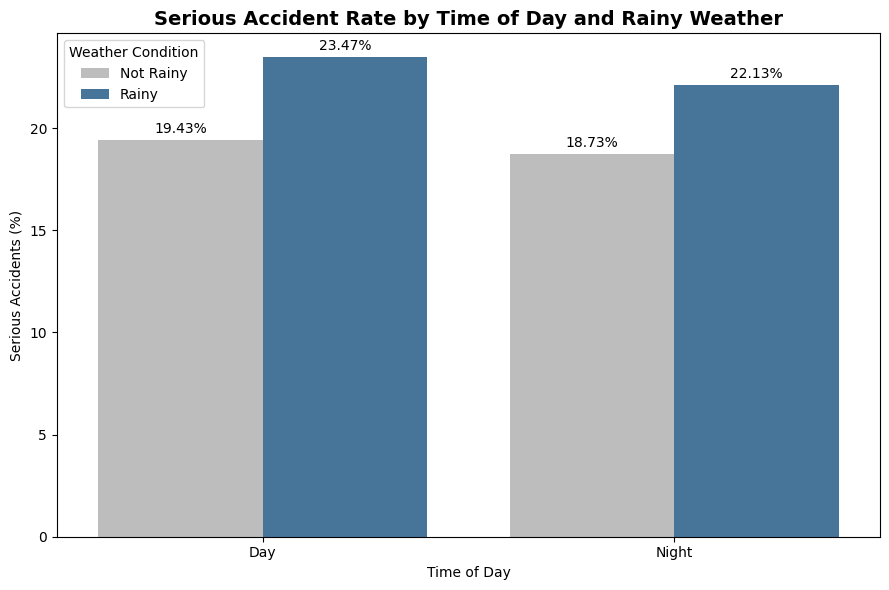

In [120]:
plt.figure(figsize=(9, 6))

sns.barplot(
    data=summary,
    x="Sunrise_Sunset",
    y="Serious_Rate",
    hue="Weather",
    palette={
        "Rainy": "#3976A8",
        "Not Rainy": "#BDBDBD"
    }
)

plt.title(
    "Serious Accident Rate by Time of Day and Rainy Weather",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Time of Day")
plt.ylabel("Serious Accidents (%)")
plt.legend(title="Weather Condition")

for container in plt.gca().containers:
    plt.bar_label(container, fmt="%.2f%%", padding=3)

plt.tight_layout()
plt.show()

In [121]:
# Create a comparison table for the rate of serious accidents
rate_table = summary.pivot(
    index="Sunrise_Sunset",
    columns="Rain",
    values="Serious_Rate"
)

# Calculate the increase due to rainfall, in percentage points
rate_table["Rain_Increase"] = rate_table[True] - rate_table[False]

rain_effect = rate_table["Rain_Increase"].reset_index()
rain_effect.columns = ["Time_of_Day", "Increase_in_Serious_Rate"]

print(rain_effect)

  Time_of_Day  Increase_in_Serious_Rate
0         Day                      4.04
1       Night                      3.39


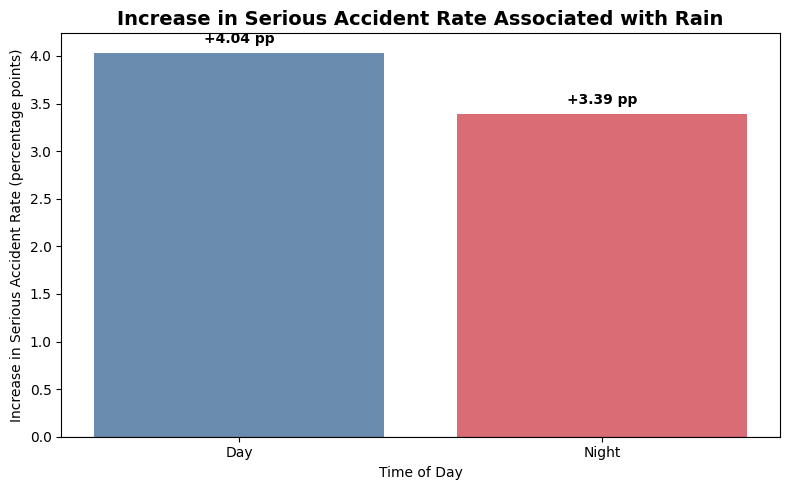

In [122]:
plt.figure(figsize=(8, 5))

bars = plt.bar(
    rain_effect["Time_of_Day"],
    rain_effect["Increase_in_Serious_Rate"],
    color=["#6A8CAF", "#D96C75"]
)

plt.title(
    "Increase in Serious Accident Rate Associated with Rain",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Time of Day")
plt.ylabel("Increase in Serious Accident Rate (percentage points)")
plt.axhline(0, color="black", linewidth=0.8)

for bar in bars:
    value = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.1,
        f"+{value:.2f} pp",
        ha="center",
        fontweight="bold"
    )

plt.tight_layout()
plt.show()